# Does shot volume predict winning in the NHL?

Do teams that take more shots win more games? I test this at two levels — within
a single game, and aggregated across a full season — and the answer turns out to
depend almost entirely on which level you ask at.

Data NHL Game Data (Martin Ellis, Kaggle). 19 regular seasons, 2000-01
through 2019-20; 2004-05 is missing from the dataset because of the lockout.

Scope Regular season only — 45,612 rows, one per team per game.

Outcome: Win rate, defined as wins / games played.

Short answer:Within a single game, shot volume barely separates winners from
losers. Across a season it explains roughly 22% of the variance in win rate — and
most of what it leaves unexplained tracks shooting percentage.

In [ ]:
import pandas as pd
df_stats = pd.read_csv('../data/game_teams_stats.csv').drop_duplicates()
df_teams = pd.read_csv('../data/team_info.csv').drop_duplicates()
df_games = pd.read_csv('../data/game.csv').drop_duplicates()


,game_id,team_id,HoA,won,settled_in,head_coach,goals,shots,hits,pim,powerPlayOpportunities,powerPlayGoals,faceOffWinPercentage,giveaways,takeaways,blocked,startRinkSide
0,2016020045,4,away,False,REG,Dave Hakstol,4.0,27.0,30.0,6.0,4.0,2.0,50.9,12.0,9.0,11.0,left
1,2016020045,16,home,True,REG,Joel Quenneville,7.0,28.0,20.0,8.0,3.0,2.0,49.1,16.0,8.0,9.0,left
2,2017020812,24,away,True,OT,Randy Carlyle,4.0,34.0,16.0,6.0,3.0,1.0,43.8,7.0,4.0,14.0,right
3,2017020812,7,home,False,OT,Phil Housley,3.0,33.0,17.0,8.0,2.0,1.0,56.2,5.0,6.0,14.0,right
4,2015020314,21,away,True,REG,Patrick Roy,4.0,29.0,17.0,9.0,3.0,1.0,45.7,13.0,5.0,20.0,left


## Data quality: duplicate rows in the raw CSVs

Both `game.csv` and `game_teams_stats.csv` ship with exact duplicate rows —
2,570 and 5,140 respectively. I found this when the season merge inflated the
joined table from ~47k rows to ~63k: duplicated `game_id` values in the lookup
table cause pandas to cross-match, multiplying rows on both sides.

Before dropping them I checked whether the duplicates were genuinely identical
or conflicting records for the same game. `drop_duplicates()` with no arguments
(which only removes rows identical across every column) brought the duplicate
`game_id` count to 0, confirming they were exact copies — likely an export
artifact rather than a data integrity problem.

Note that ~47,470 rows in the merged table is correct, not inflated:
`game_teams_stats` is one row per team per game, so every game contributes two
rows (home and away).

## Building the analysis table

Two joins, both inner:

1. **`game_teams_stats` + `team_info` on `team_id`** — adds team names to the
   stat rows. Drops 10 rows: team_ids 87–90 are All-Star squads with no entry in
   `team_info`. Fine by me, I don't want them.
2. **+ `game` on `game_id`** — adds `season`. I filter `game` to `type == 'R'`
   first, so this join also drops the playoff games. 47,460 → 45,612.

Inner joins on purpose. A left join would keep the All-Star and playoff rows with
nulls, and I'd just have to drop them later anyway.

**Regular season only** chose because playoff participation depends on team quality —
good teams play more playoff games, which would bias the thing I'm measuring.

**Result: 45,612 rows = 22,806 games × 2 teams**, one row per team per game.
Any other number means a join went wrong.

*Note:* 33 `team_id`s but only 32 `teamName`s — Phoenix and Arizona both map to
"Coyotes". Grouping by name later merges them, which is what I want.

In [2]:
df_games_reg = df_games[df_games['type'] == 'R']

df = pd.merge(df_teams, df_stats, on='team_id')
df = pd.merge(df, df_games_reg[['game_id', 'season']], on='game_id')
df.shape



(45612, 23)

In [3]:


df.groupby('won')['shots'].mean()



won
False    29.559059
True     29.930336
Name: shots, dtype: float64

### Result: essentially no separation

> **TODO —** 29.93 vs 29.56 shots, a gap of 0.37 (~1.3%).
>
> **Then the caveat, which matters more than the result:** score effects. Teams
> that fall behind shoot more; teams protecting a lead sit back. That pushes the
> two groups toward each other and could be masking a real relationship. Write
> out why this makes the null result weak evidence rather than a finding.


In [4]:
team_season = df.groupby(['teamName', 'season']).agg(
    total_shots=('shots', 'sum'),
    total_goals=('goals', 'sum'),
    total_wins=('won', 'sum'),
    games_played=('won', 'count')
).reset_index()
team_season['win_rate'] = team_season['total_wins'] / team_season['games_played']
team_season['shots_per_game'] = team_season['total_shots'] / team_season['games_played']
team_season['shooting_pct'] = team_season['total_goals'] / team_season['total_shots']

In [5]:
import numpy as np

slope, intercept = np.polyfit(team_season['shots_per_game'], team_season['win_rate'], 1)
team_season['expected_win_rate'] = slope * team_season['shots_per_game'] + intercept
team_season['residual'] = team_season['win_rate'] - team_season['expected_win_rate']

## Finding 2: Over a season, shot volume matters moderately

Aggregated to team-season (573 rows), shots per game and win rate correlate at
**r = 0.469**, so shot volume explains about **22%** of the variation in win rate.
Each extra shot per game is worth roughly 2 points of win rate (~1.7 wins over
82 games).

The relationship only shows up at this level because single-game noise averages
out over a season.
But the spread is large: teams averaging ~30 shots/game ranged from a **.317 to
a .750** win rate. Volume alone leaves most of the story unexplained, which is
what Finding 3 looks at.

In [6]:
team_season['shots_per_game'].corr(team_season['win_rate'])

np.float64(0.46934810815510564)

Correlation between shots per game and win rate is 0.469 moderate positive relationship

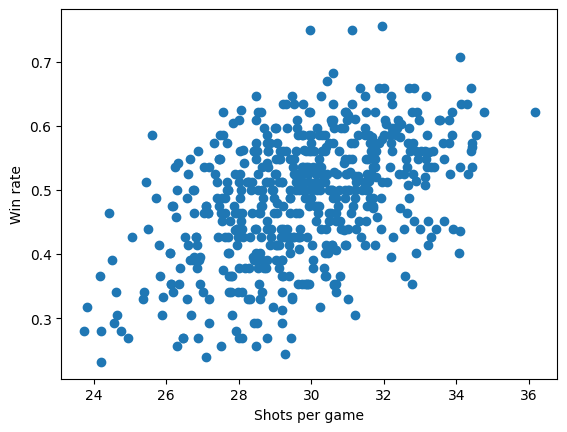

In [7]:
import matplotlib.pyplot as plt

plt.scatter(team_season['shots_per_game'], team_season['win_rate'])
plt.xlabel('Shots per game')
plt.ylabel('Win rate')
plt.show()

In [11]:
team_season_pct = df.groupby(['teamName','season']).agg(
    total_goals=('goals','sum'),
    total_shots=('shots','sum')
).reset_index()
team_season_pct['shooting_pct'] = team_season_pct['total_goals'] / team_season_pct['total_shots']


In [12]:
team_season['shots_per_game'].corr(team_season['win_rate'])

np.float64(0.46934810815510564)

In [13]:
team_season['shooting_pct'].corr(team_season['residual'])

np.float64(0.5958608997963166)

### Result: shooting pct correlates 0.59 with the residual



### Who over- and under-performed their shot volume?

> **TODO —** Walk through the named examples rather than just printing tables:
> - Pittsburgh (Crosby/Malkin) as the top overperformer — high conversion, expected.
> - Canadiens 2017-18 as the cleanest illustration: 32.8 shots/game, .354 win
>   rate, .077 shooting. High volume, bad finishing, bad season.
> - **The counter-evidence:** Flyers 2006-07 (.0902) and Kings 2006-07 (.0877)
>   converted at roughly league average and still underperformed badly. Put this
>   next to the tables, not in a footnote — it is evidence against your own
>   framing, and it points at goals-against, which this analysis cannot see.


In [ ]:
team_season.nlargest(10, 'residual')[['teamName','season','shots_per_game','win_rate','shooting_pct','residual']]

,teamName,season,shots_per_game,win_rate,shooting_pct,residual
403,Penguins,20122013,29.958333,0.750000,0.112656,0.258847
30,Blackhawks,20122013,31.125000,0.750000,0.099732,0.234639
333,Lightning,20182019,31.951220,0.756098,0.121756,0.223593
529,Stars,20052006,28.487805,0.646341,0.108305,0.185702
525,Stars,20002001,25.609756,0.585366,0.114762,0.184445
416,Predators,20062007,27.573171,0.621951,0.117647,0.180290
147,Capitals,20152016,30.609756,0.682927,0.098805,0.178257
201,Ducks,20122013,28.062500,0.625000,0.099480,0.173185
148,Capitals,20162017,30.426829,0.670732,0.104609,0.169858
473,Sabres,20062007,29.475610,0.646341,0.123293,0.165205


In [15]:
team_season.nsmallest(10, 'residual')[['teamName','season','shots_per_game','win_rate','shooting_pct','residual']]

,teamName,season,shots_per_game,win_rate,shooting_pct,residual
22,Blackhawks,20032004,29.280488,0.243902,0.078301,-0.233185
252,Hurricanes,20022003,29.439024,0.268293,0.070837,-0.212085
484,Sabres,20172018,31.195122,0.304878,0.077404,-0.211938
61,Blues,20052006,28.475610,0.256098,0.082655,-0.204289
233,Flyers,20062007,28.792683,0.268293,0.090216,-0.198673
111,Canadiens,20172018,32.768293,0.353659,0.077038,-0.195800
467,Red Wings,20192020,27.098592,0.239437,0.073805,-0.192377
269,Islanders,20002001,27.524390,0.256098,0.081967,-0.184552
15,Avalanche,20162017,28.097561,0.268293,0.071615,-0.184250
302,Kings,20062007,31.000000,0.329268,0.087726,-0.183499


In [16]:
team_season['shooting_pct'].mean()

np.float64(0.09300734547900667)

## Limitations

> **TODO —** No shot-quality data (no xG), so all shots count the same.
> Shooting percentage conflates skill and luck. The analysis is offense-only —
> it has nothing to say about goaltending or defence, which the 2006-07 Flyers
> and Kings show is a real gap, not a hypothetical one.

## Still open

> **TODO —** Direct shooting pct vs win rate correlation (to compare head-to-head
> with 0.469); robustness check on full seasons only (`games_played >= 70`);
> correlation trend across the 19 seasons; shooting pct year-over-year
> persistence, to separate skill from luck.
